In [63]:
import pyarrow.dataset as ds
from functools import reduce
from datetime import datetime
import stream_utils.S3hsclient as hsclient

import pyarrow.parquet as pq
from datetime import datetime
import geopandas as gpd


In [24]:
root_dir = Path('stream-v1-data-original')
pq_dir = Path('stream-v1-data-parquet')
pq_dir.mkdir(exist_ok=True)

Create Metadata Parquet

In [86]:
metadata_path = pq_dir / "metadata.parquet"
lulc_path =  pq_dir / 'dynamic_lulc.parquet'
anthro_path = pq_dir / 'dynamic_anthropogenic.parquet'
grab_path = pq_dir / 'grab_samples.parquet'
watershed_path = pq_dir / 'watersheds.parquet'
discharge_path = pq_dir / 'streamflow_discharge'
meteorology_path = pq_dir / 'dynamic_historical_meteorology'

## Test Querying Metadata

In [28]:
dataset = ds.dataset(
            metadata_path,
            format="parquet",
            )
metadata = dataset.to_table().to_pandas()


In [30]:
metadata.head(2)

,STREAM_ID,site_name,source,sourceID,latitude_wgs84,longitude_wgs84,state_name,time_zone,WQ_parameters,grabsamples,streamflow,COMID,catchment_shapefile_source,catchmentarea_km2,source_catchmentarea_km2,catchmentarea_variability_%,flag_catchment_shapefile,hydro_impacts
0,STREAM-gauge-1,LEAF RIVER NEAR HATTIESBURG,USGS,02473085,31.306583,-89.264111,Mississippi,Central,"WTemp_C,DO_mgL,pH",NaN,Not available,18135842.0,USGS_LID,4586.015222,NaN,NaN,NaN,NaN
1,STREAM-gauge-2,"LEAF RIVER NR NEW AUGUSTA, MS",USGS,02474560,31.221667,-89.053056,Mississippi,Central,WTemp_C,NaN,Available,18135958.0,USGS_LID,6603.581129,6583.75458,0.301144,Safe,NaN


## Test Querying LULC

In [38]:
%%time
dataset = ds.dataset(
            lulc_path,
            format="parquet",
            )
lulc = dataset.to_table().to_pandas()
#lulc.head(2)

CPU times: user 34.5 ms, sys: 17.6 ms, total: 52.1 ms
Wall time: 17.7 ms


In [39]:
%%time

gauge = 'STREAM-gauge-1665'
st = datetime(2018, 10, 1)
et = datetime(2020, 3, 1)

table = pq.read_table(
    lulc_path,
    filters = [
        ('STREAM_ID', '=', gauge),
        ('DateTime', '>=', st),
        ('DateTime', '<=', et)
    ]
)

table.to_pandas()

CPU times: user 25.8 ms, sys: 5.54 ms, total: 31.3 ms
Wall time: 12.9 ms


,DateTime,Open Water,Perennial Ice/Snow,Developed Open Space,Developed Low Intensity,Developed Medium Intensity,Developed High Intensity,Barren Land,Deciduous Forest,Evergreen Forest,Mixed Forest,Shrub/Scrub,Grassland/Herbaceous,Pasture/Hay,Cultivated Crops,Woody Wetlands,Emergent Herbaceous Wetlands,STREAM_ID
0,2019-01-01,0.007611,0.0,0.142509,0.098326,0.052616,0.016336,0.008639,0.337658,0.001834,0.037967,0.002388,0.002573,0.140652,0.137397,0.013086,0.000407,STREAM-gauge-1665
1,2020-01-01,0.007482,0.0,0.143657,0.098389,0.052796,0.016440,0.008684,0.337360,0.001837,0.037855,0.002323,0.002755,0.140462,0.136438,0.013093,0.000429,STREAM-gauge-1665


## Test Querying Dynamic Anthropogenic

In [43]:
%%time
dataset = ds.dataset(
            anthro_path,
            format="parquet",
            )
anthro = dataset.to_table().to_pandas()
anthro.head(2)

CPU times: user 41.4 ms, sys: 9.14 ms, total: 50.5 ms
Wall time: 17.9 ms


,DateTime,so4_tw,cl_tw,no3_tw,na_tw,k_tw,ca_tw,mg_tw,nh4_tw,salt_pound,nfer,pfer,fertnkg,fertpkg,manurenkg,manurepkg,irrig,STREAM_ID
0,1980-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11.705096,2.273845,21.301277,6.743142,0.0,STREAM-gauge-1
1,1981-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.886522,2.267485,20.756225,6.454274,0.0,STREAM-gauge-1


In [51]:
%%time

gauge = 'STREAM-gauge-1665'
st = datetime(2010, 10, 1)
et = datetime(2020, 3, 1)

table = pq.read_table(
    anthro_path,
    filters = [
        ('STREAM_ID', '=', gauge),
        ('DateTime', '>=', st),
        ('DateTime', '<=', et)
    ]
)

table.to_pandas()

CPU times: user 32.4 ms, sys: 5.56 ms, total: 37.9 ms
Wall time: 14.9 ms


,DateTime,so4_tw,cl_tw,no3_tw,na_tw,k_tw,ca_tw,mg_tw,nh4_tw,salt_pound,nfer,pfer,fertnkg,fertpkg,manurenkg,manurepkg,irrig,STREAM_ID
0,2011-01-01,14.714507,4.281014,13.901707,2.386291,0.452807,1.550244,0.428774,4.353417,39216.787475,9.560,1.275,13.763606,1.948413,19.960809,5.654100,0.002279,STREAM-gauge-1665
1,2012-01-01,9.773235,2.918905,11.383413,1.954055,0.419351,1.482863,0.367265,3.716060,21948.150769,9.010,1.335,13.594197,2.029075,19.881435,5.630617,0.002965,STREAM-gauge-1665
2,2013-01-01,8.802997,2.937095,10.142895,1.648305,0.581374,1.201515,0.341632,3.996179,42678.794241,9.865,1.445,13.906358,2.050810,20.116472,5.697400,0.001936,STREAM-gauge-1665
3,2014-01-01,8.496578,4.493827,10.556627,2.642720,0.405582,1.425410,0.464501,3.410295,47859.392059,NaN,NaN,14.078499,2.237627,20.775400,5.874047,0.003308,STREAM-gauge-1665
4,2015-01-01,5.969527,3.942660,8.738369,2.278831,0.344117,1.006846,0.320948,3.453483,55636.492834,NaN,NaN,17.977730,3.467853,22.176070,6.123970,0.003707,STREAM-gauge-1665
5,2016-01-01,5.278559,4.256035,8.410665,2.432692,0.370106,1.193964,0.432295,3.867309,31433.644903,NaN,NaN,18.880518,3.550875,21.931868,6.046025,0.003404,STREAM-gauge-1665
6,2017-01-01,4.996788,4.865044,7.926245,2.649303,0.350004,1.030604,0.412951,3.045943,42358.298292,NaN,NaN,18.099503,3.479626,22.013648,6.076640,0.003061,STREAM-gauge-1665
7,2018-01-01,6.012734,4.064338,10.660052,2.260070,0.408438,1.262260,0.367058,4.103922,48804.217065,NaN,NaN,18.129864,3.568019,22.235488,6.132235,0.003061,STREAM-gauge-1665
8,2019-01-01,5.808159,5.372769,9.835606,2.984294,0.484239,1.232883,0.465891,3.959047,45084.313070,NaN,NaN,17.308494,3.479309,22.013021,6.073750,0.002718,STREAM-gauge-1665
9,2020-01-01,4.272418,2.586380,7.691192,1.492164,0.304560,1.144302,0.278984,3.590882,NaN,NaN,NaN,18.552977,3.543295,22.047485,6.085118,0.003404,STREAM-gauge-1665


## Test Querying Grab Samples

In [46]:
%%time
dataset = ds.dataset(
            grab_path,
            format="parquet",
            )
grab = dataset.to_table().to_pandas()
grab.head(2)

CPU times: user 40.6 ms, sys: 14.3 ms, total: 54.9 ms
Wall time: 25.6 ms


,DateTime,TSS_mgL,NO3_mgNL,DOC_mgL,PO4_mgPL,Cl_mgL,Chla_ugL,STREAM_ID,SSC_mgL,PC_ugL
0,1959-10-01,NaN,NaN,NaN,NaN,25.0,NaN,STREAM-gauge-1014,NaN,NaN
1,1959-10-03,NaN,NaN,NaN,NaN,17.0,NaN,STREAM-gauge-1014,NaN,NaN


In [50]:
%%time

gauge = 'STREAM-gauge-838'
st = datetime(2010, 10, 1)
et = datetime(2026, 3, 1)

table = pq.read_table(
    grab_path,
    filters = [
        ('STREAM_ID', '=', gauge),
        ('DateTime', '>=', st),
        ('DateTime', '<=', et)
    ]
)

table.to_pandas()

CPU times: user 34.3 ms, sys: 2.68 ms, total: 37 ms
Wall time: 16.4 ms


,DateTime,TSS_mgL,NO3_mgNL,DOC_mgL,PO4_mgPL,Cl_mgL,Chla_ugL,STREAM_ID,SSC_mgL,PC_ugL
0,2010-10-13 13:00:00,NaN,NaN,NaN,NaN,NaN,NaN,STREAM-gauge-838,123.0,NaN
1,2010-10-14 05:00:00,NaN,NaN,NaN,NaN,NaN,NaN,STREAM-gauge-838,117.0,NaN
2,2010-10-14 13:00:00,NaN,NaN,NaN,NaN,NaN,NaN,STREAM-gauge-838,109.0,NaN
3,2010-10-14 21:00:00,NaN,NaN,NaN,NaN,NaN,NaN,STREAM-gauge-838,113.0,NaN
4,2010-10-15 05:00:00,NaN,NaN,NaN,NaN,NaN,NaN,STREAM-gauge-838,103.0,NaN
...,...,...,...,...,...,...,...,...,...,...
4288,2025-07-25 12:00:00,NaN,NaN,NaN,NaN,NaN,NaN,STREAM-gauge-838,35.0,NaN
4289,2025-07-27 12:00:00,NaN,NaN,NaN,NaN,NaN,NaN,STREAM-gauge-838,216.0,NaN
4290,2025-07-28 12:00:00,NaN,NaN,NaN,NaN,NaN,NaN,STREAM-gauge-838,83.0,NaN
4291,2025-07-29 11:00:00,NaN,NaN,NaN,NaN,NaN,NaN,STREAM-gauge-838,122.0,NaN


## Test Querying Watersheds

In [54]:
%%time
dataset = ds.dataset(
            watershed_path,
            format="parquet",
            )
watersheds = dataset.to_table().to_pandas()
watersheds.head(2)

CPU times: user 21.7 ms, sys: 56.4 ms, total: 78.1 ms
Wall time: 86.1 ms


,STREAM_ID,COMID,area_km2,geometry
0,STREAM-gauge-2864,8931712,4061.880515,b'\x01\x03\x00\x00\x00\x05\x00\x00\x00\xcf\x02...
1,STREAM-gauge-875,24534322,95.430504,b'\x01\x03\x00\x00\x00\x01\x00\x00\x00h\x00\x0...


Found 1424 watersheds.
Here's the geometry of the first one:
CPU times: user 21.9 ms, sys: 61.9 ms, total: 83.8 ms
Wall time: 90.7 ms


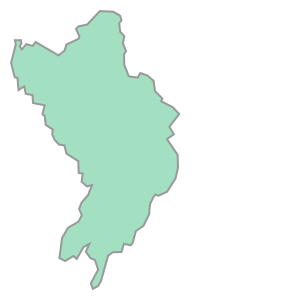

In [73]:
%%time

area_threshold = 100

table = pq.read_table(
    watershed_path,
    filters = [
        ('area_km2', '<', area_threshold),
    ]
)
#table.to_pandas()

gdf = gpd.GeoDataFrame.from_arrow(table)

print(f"Found {len(gdf)} watersheds.")
print("Here's the geometry of the first one:")
gdf.iloc[0].geometry


## Test Querying Stream Discharge

In [79]:
%%time
dataset = ds.dataset(
            discharge_path,
            format="parquet",
            partitioning='hive'
            )

gauges = ["STREAM-gauge-1618",
          "STREAM-gauge-1619",
          "STREAM-gauge-1620"]

result = dataset.to_table(
    filter=(
        (ds.field("STREAM_ID").isin(gauges)) &
        (ds.field("DateTime") >= datetime(2001, 1, 1)) &
        (ds.field("DateTime") < datetime(2010, 1, 1))
    )
)


CPU times: user 28.5 ms, sys: 60.4 ms, total: 88.9 ms
Wall time: 76.4 ms


In [81]:
df = result.to_pandas()

In [82]:
df.STREAM_ID.unique()

<ArrowStringArray>
['STREAM-gauge-1618', 'STREAM-gauge-1619', 'STREAM-gauge-1620']
Length: 3, dtype: str

<Axes: xlabel='DateTime'>

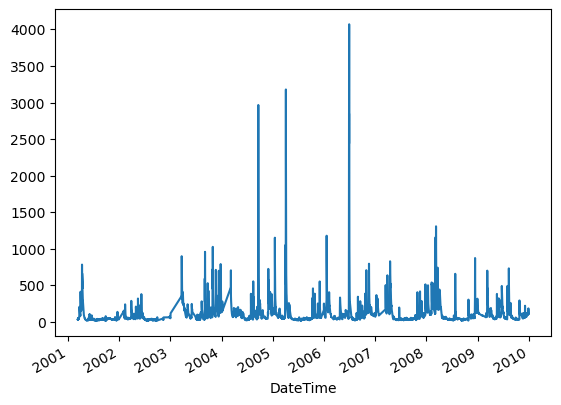

In [85]:
df.loc[df.STREAM_ID == gauges[0]] \
    .set_index('DateTime')['Q_m3s'] \
    .plot()

## Test Querying Historical Meteorology

In [92]:
%%time
dataset = ds.dataset(
            meteorology_path,
            format="parquet",
            partitioning='hive'
            )

gauges = ["STREAM-gauge-147",
          "STREAM-gauge-427",
          "STREAM-gauge-704"]

result = dataset.to_table(
    filter=(
        (ds.field("STREAM_ID").isin(gauges)) &
        (ds.field("DateTime") >= datetime(2001, 1, 1)) &
        (ds.field("DateTime") < datetime(2010, 1, 1))
    )
)


CPU times: user 46.2 ms, sys: 45.2 ms, total: 91.3 ms
Wall time: 37.7 ms


In [93]:
df = result.to_pandas()

In [94]:
df.STREAM_ID.unique()

<ArrowStringArray>
['STREAM-gauge-147', 'STREAM-gauge-427', 'STREAM-gauge-704']
Length: 3, dtype: str

In [95]:
df.loc[df.STREAM_ID == gauges[0]]

,DateTime,APCP_surface,DLWRF_surface,DSWRF_surface,PRES_surface,SPFH_2maboveground,TMP_2maboveground,UGRD_10maboveground,VGRD_10maboveground,STREAM_ID
0,2001-01-01,0.0,195.584991,0.000000,93080.960938,0.001804,267.161621,7.008175,-4.527767,STREAM-gauge-147
1,2001-01-01,0.0,195.252274,0.000000,93156.390625,0.001798,266.360718,6.819696,-4.502849,STREAM-gauge-147
2,2001-01-01,0.0,194.917664,0.000000,93236.765625,0.001792,265.558014,6.629853,-4.483987,STREAM-gauge-147
3,2001-01-01,0.0,185.743896,0.000000,93311.218750,0.001789,264.758026,6.421118,-4.448340,STREAM-gauge-147
4,2001-01-01,0.0,185.528915,0.000000,93293.578125,0.001734,264.337738,5.921118,-4.321065,STREAM-gauge-147
...,...,...,...,...,...,...,...,...,...,...
78883,2009-12-31,0.0,298.358124,134.246155,93103.750000,0.003648,273.358337,2.302934,3.300000,STREAM-gauge-147
78884,2009-12-31,0.0,298.533295,100.998207,93101.921875,0.003677,273.306610,1.726419,3.399177,STREAM-gauge-147
78885,2009-12-31,0.0,305.594086,56.160114,93099.515625,0.003741,273.211853,1.126419,3.482585,STREAM-gauge-147
78886,2009-12-31,0.0,303.967712,0.603661,93061.757812,0.003615,272.465271,1.713768,3.002881,STREAM-gauge-147


<Axes: xlabel='DateTime'>

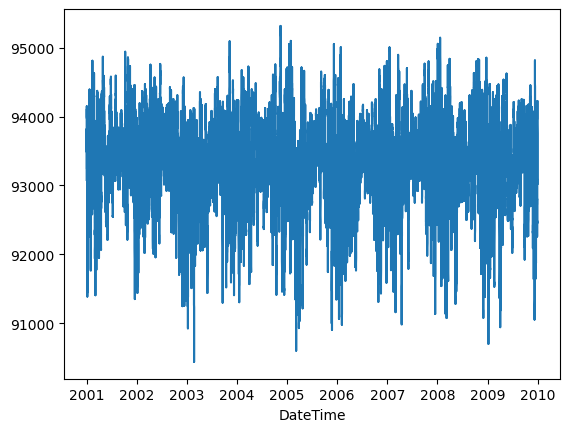

In [96]:
df.loc[df.STREAM_ID == gauges[0]] \
    .set_index('DateTime')['PRES_surface'] \
    .plot();